# API Security Framework: Automated BOLA Detection

**Project:** API Security Framework: automated OWASP ZAP and Postman collections to check for
**BOLA (Broken Object Level Authorization)** flaws, ranked #1 in the OWASP API Security Top 10.

**What this notebook does**

1. Starts a small *demo API* that contains realistic BOLA flaws (so the notebook runs end-to-end anywhere).
2. Runs an automated **two-user BOLA test engine**: user A requests user B's objects on every endpoint and HTTP method.
3. Classifies every result (`VULNERABLE` / `SECURE` / `INCONCLUSIVE`) and assigns a severity.
4. Generates a **Postman collection + environment** from the same test matrix and runs it with **Newman** (when installed).
5. Drives an **OWASP ZAP** spider and active scan through its API (when a ZAP daemon is reachable).
6. Exports CSV/JSON/Markdown reports and a CI-style pass/fail gate.

> **Scope and ethics:** only run these tests against APIs you own or have written permission to test.
> To test your own API instead of the demo, edit the **Configuration** cell.

## 1. Setup and configuration

In [1]:
import copy
import json
import logging
import os
import shutil
import subprocess
import threading
import time

import matplotlib.pyplot as plt
import pandas as pd
import requests
from flask import Flask, jsonify, request
from werkzeug.serving import make_server

logging.getLogger("werkzeug").setLevel(logging.ERROR)  # keep demo-server request logs out of the notebook
OUTPUT_DIR = "output"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# ---------------- Configuration ----------------
USE_DEMO_API = True                 # False -> test your own API (set BASE_URL, USERS, RESOURCES, ENDPOINTS)
BASE_URL = "http://127.0.0.1:5001"
RESET_URL = BASE_URL + "/_reset"    # optional endpoint that restores seed data (None for real targets)
ALLOW_DESTRUCTIVE = True            # allow PUT/DELETE tests (keep True only on disposable test data)

# Test accounts: at least two users are required for object-level tests.
USERS = {
    "alice": {"username": "alice", "password": "alice123"},
    "bob":   {"username": "bob",   "password": "bob123"},
    "carol": {"username": "carol", "password": "carol123"},
}

# Object IDs each user legitimately owns, grouped by resource type.
RESOURCES = {
    "orders":   {"alice": [101, 102], "bob": [201, 202], "carol": [301]},
    "profiles": {"alice": [1], "bob": [2], "carol": [3]},
}

# Endpoint templates. {id} is replaced with the victim's object ID.
ENDPOINTS = [
    {"name": "v1 GET order",      "method": "GET",    "path": "/api/v1/orders/{id}",       "resource": "orders",   "sensitive": False},
    {"name": "v1 PUT order",      "method": "PUT",    "path": "/api/v1/orders/{id}",       "resource": "orders",   "sensitive": False, "body": {"note": "tampered"}},
    {"name": "v1 DELETE order",   "method": "DELETE", "path": "/api/v1/orders/{id}",       "resource": "orders",   "sensitive": False},
    {"name": "v1 GET profile",    "method": "GET",    "path": "/api/v1/users/{id}/profile", "resource": "profiles", "sensitive": True},
    {"name": "v2 GET order",      "method": "GET",    "path": "/api/v2/orders/{id}",       "resource": "orders",   "sensitive": False},
    {"name": "v2 PUT order",      "method": "PUT",    "path": "/api/v2/orders/{id}",       "resource": "orders",   "sensitive": False, "body": {"note": "tampered"}},
    {"name": "v2 DELETE order",   "method": "DELETE", "path": "/api/v2/orders/{id}",       "resource": "orders",   "sensitive": False},
    {"name": "v2 GET profile",    "method": "GET",    "path": "/api/v2/users/{id}/profile", "resource": "profiles", "sensitive": True},
]
print(f"Configured {len(USERS)} users and {len(ENDPOINTS)} endpoint/method combinations.")

Configured 3 users and 8 endpoint/method combinations.

## 2. Demo target API (intentionally flawed)

* **v1** performs authentication only: any logged-in user can read, change or delete any object (classic BOLA).
* **v2** is the "fixed" version, but the `DELETE` handler was missed: a realistic *partial fix* that automated testing should catch.

In [2]:
def build_demo_api():
    app = Flask(__name__)
    credentials = {u["username"]: u["password"] for u in USERS.values()}
    tokens = {}

    seed_orders = {
        101: {"owner": "alice", "item": "Laptop",   "note": "alice-private"},
        102: {"owner": "alice", "item": "Monitor",  "note": "alice-private"},
        201: {"owner": "bob",   "item": "Phone",    "note": "bob-private"},
        202: {"owner": "bob",   "item": "Tablet",   "note": "bob-private"},
        301: {"owner": "carol", "item": "Keyboard", "note": "carol-private"},
    }
    seed_profiles = {
        1: {"owner": "alice", "email": "alice@example.com", "address": "12 Park Street"},
        2: {"owner": "bob",   "email": "bob@example.com",   "address": "7 Lake Road"},
        3: {"owner": "carol", "email": "carol@example.com", "address": "91 Hill Avenue"},
    }
    state = {"orders": copy.deepcopy(seed_orders), "profiles": copy.deepcopy(seed_profiles)}

    def current_user():
        header = request.headers.get("Authorization", "")
        return tokens.get(header[7:]) if header.startswith("Bearer ") else None

    @app.post("/login")
    def login():
        data = request.get_json(silent=True) or {}
        if data.get("username") in credentials and credentials[data["username"]] == data.get("password"):
            token = f"tok-{data['username']}-{len(tokens) + 1}"
            tokens[token] = data["username"]
            return jsonify(token=token)
        return jsonify(error="bad credentials"), 401

    @app.post("/_reset")
    def reset():
        state["orders"] = copy.deepcopy(seed_orders)
        state["profiles"] = copy.deepcopy(seed_profiles)
        return jsonify(status="reset")

    def register(version, enforce_orders, enforce_profile):
        def order_view(order_id):
            user = current_user()
            if not user:
                return jsonify(error="unauthenticated"), 401
            order = state["orders"].get(order_id)
            if order is None:
                return jsonify(error="not found"), 404
            if enforce_orders[request.method] and order["owner"] != user:
                return jsonify(error="forbidden"), 403
            if request.method == "GET":
                return jsonify(id=order_id, **order)
            if request.method == "PUT":
                order["note"] = (request.get_json(silent=True) or {}).get("note", order["note"])
                return jsonify(id=order_id, **order)
            del state["orders"][order_id]
            return jsonify(deleted=order_id)

        def profile_view(user_id):
            user = current_user()
            if not user:
                return jsonify(error="unauthenticated"), 401
            profile = state["profiles"].get(user_id)
            if profile is None:
                return jsonify(error="not found"), 404
            if enforce_profile and profile["owner"] != user:
                return jsonify(error="forbidden"), 403
            return jsonify(id=user_id, **profile)

        app.add_url_rule(f"/api/{version}/orders/<int:order_id>", endpoint=f"orders_{version}",
                         view_func=order_view, methods=["GET", "PUT", "DELETE"])
        app.add_url_rule(f"/api/{version}/users/<int:user_id>/profile", endpoint=f"profile_{version}",
                         view_func=profile_view, methods=["GET"])

    # v1: no object-level checks at all
    register("v1", {"GET": False, "PUT": False, "DELETE": False}, enforce_profile=False)
    # v2: checks added for GET/PUT/profile, DELETE forgotten (partial fix)
    register("v2", {"GET": True, "PUT": True, "DELETE": False}, enforce_profile=True)
    return app


class DemoServer(threading.Thread):
    def __init__(self, app, port):
        super().__init__(daemon=True)
        self.server = make_server("127.0.0.1", port, app, threaded=True)

    def run(self):
        self.server.serve_forever()

    def stop(self):
        self.server.shutdown()


demo_server = None
if USE_DEMO_API:
    demo_server = DemoServer(build_demo_api(), 5001)
    demo_server.start()
    for _ in range(30):
        try:
            requests.post(BASE_URL + "/login", json={}, timeout=1)
            break
        except requests.ConnectionError:
            time.sleep(0.2)
    print("Demo API running at", BASE_URL)

Demo API running at http://127.0.0.1:5001

## 3. BOLA test engine

For every `(endpoint, object, owner, attacker)` combination the engine:

1. **Baseline:** confirms the owner can access their own object (avoids false positives from broken test data).
2. **Attack:** the attacker requests the victim's object with the attacker's own valid token.
3. **Verdict:** `2xx` = **VULNERABLE** (and notes whether the victim's data was leaked); `401/403/404` = **SECURE**; anything else = **INCONCLUSIVE**.
4. Also checks each endpoint **without any token** (broken authentication / missing auth).

In [3]:
def login(user):
    response = requests.post(f"{BASE_URL}/login", json=USERS[user], timeout=10)
    response.raise_for_status()
    return response.json()["token"]


def reset_state():
    if RESET_URL:
        requests.post(RESET_URL, timeout=10)


def send(method, path, token=None, body=None):
    headers = {"Authorization": f"Bearer {token}"} if token else {}
    return requests.request(method, BASE_URL + path, headers=headers, json=body, timeout=10)


def severity(endpoint):
    if endpoint["method"] == "DELETE":
        return "Critical"
    if endpoint["method"] in ("PUT", "PATCH", "POST"):
        return "High"
    return "High" if endpoint.get("sensitive") else "Medium"


def leaked_victim_data(response, victim):
    try:
        return response.json().get("owner") == victim
    except ValueError:
        return False


def run_bola_tests():
    tokens = {user: login(user) for user in USERS}
    rows = []
    for endpoint in ENDPOINTS:
        method = endpoint["method"]
        if method in ("PUT", "PATCH", "DELETE", "POST") and not ALLOW_DESTRUCTIVE:
            continue
        for victim, object_ids in RESOURCES[endpoint["resource"]].items():
            for object_id in object_ids:
                path = endpoint["path"].format(id=object_id)
                for attacker in USERS:
                    if attacker == victim:
                        continue
                    # 1) baseline: owner can reach own object (skipped for DELETE: it would consume the object)
                    reset_state()
                    baseline = "n/a"
                    if method != "DELETE":
                        baseline = send(method, path, tokens[victim], endpoint.get("body")).status_code
                    # 2) attack: attacker uses own token on victim's object
                    reset_state()
                    response = send(method, path, tokens[attacker], endpoint.get("body"))
                    status = response.status_code
                    if baseline not in ("n/a",) and not (200 <= baseline < 300):
                        verdict = "INCONCLUSIVE"
                    elif 200 <= status < 300:
                        verdict = "VULNERABLE"
                    elif status in (401, 403, 404):
                        verdict = "SECURE"
                    else:
                        verdict = "INCONCLUSIVE"
                    rows.append({
                        "endpoint": endpoint["name"], "method": method, "path": path,
                        "victim": victim, "attacker": attacker, "object_id": object_id,
                        "baseline_status": baseline, "attack_status": status, "verdict": verdict,
                        "data_leaked": leaked_victim_data(response, victim) if method == "GET" and verdict == "VULNERABLE" else False,
                        "severity": severity(endpoint) if verdict == "VULNERABLE" else "-",
                    })
        # 3) unauthenticated check, once per endpoint
        sample_id = next(iter(next(iter(RESOURCES[endpoint["resource"]].values()))))
        reset_state()
        status = send(method, endpoint["path"].format(id=sample_id), None, endpoint.get("body")).status_code
        rows.append({
            "endpoint": endpoint["name"], "method": method, "path": endpoint["path"].format(id=sample_id),
            "victim": "-", "attacker": "(no token)", "object_id": sample_id,
            "baseline_status": "n/a", "attack_status": status,
            "verdict": "SECURE" if status in (401, 403) else ("VULNERABLE" if 200 <= status < 300 else "INCONCLUSIVE"),
            "data_leaked": False,
            "severity": "Critical" if 200 <= status < 300 else "-",
        })
    reset_state()
    return pd.DataFrame(rows)


results = run_bola_tests()
print(f"Executed {len(results)} test cases.")
results.head(10)

Executed 80 test cases.

,endpoint,method,path,victim,attacker,object_id,baseline_status,attack_status,verdict,data_leaked,severity
0,v1 GET order,GET,/api/v1/orders/101,alice,bob,101,200,200,VULNERABLE,True,Medium
1,v1 GET order,GET,/api/v1/orders/101,alice,carol,101,200,200,VULNERABLE,True,Medium
2,v1 GET order,GET,/api/v1/orders/102,alice,bob,102,200,200,VULNERABLE,True,Medium
3,v1 GET order,GET,/api/v1/orders/102,alice,carol,102,200,200,VULNERABLE,True,Medium
4,v1 GET order,GET,/api/v1/orders/201,bob,alice,201,200,200,VULNERABLE,True,Medium
5,v1 GET order,GET,/api/v1/orders/201,bob,carol,201,200,200,VULNERABLE,True,Medium
6,v1 GET order,GET,/api/v1/orders/202,bob,alice,202,200,200,VULNERABLE,True,Medium
7,v1 GET order,GET,/api/v1/orders/202,bob,carol,202,200,200,VULNERABLE,True,Medium
8,v1 GET order,GET,/api/v1/orders/301,carol,alice,301,200,200,VULNERABLE,True,Medium
9,v1 GET order,GET,/api/v1/orders/301,carol,bob,301,200,200,VULNERABLE,True,Medium


## 4. Results

In [4]:
summary = (results.pivot_table(index="endpoint", columns="verdict", values="path", aggfunc="count", fill_value=0)
           .reindex([e["name"] for e in ENDPOINTS]))
for column in ("VULNERABLE", "SECURE", "INCONCLUSIVE"):
    if column not in summary:
        summary[column] = 0
summary = summary[["VULNERABLE", "SECURE", "INCONCLUSIVE"]]
summary["exposure_%"] = (100 * summary["VULNERABLE"] / summary.sum(axis=1)).round(1)
print(summary.to_string())

total_vulnerable = int((results["verdict"] == "VULNERABLE").sum())
print(f"\nTotal vulnerable test cases: {total_vulnerable} of {len(results)} "
      f"({100 * total_vulnerable / len(results):.1f}%)")

verdict          VULNERABLE  SECURE  INCONCLUSIVE  exposure_%
endpoint                                                     
v1 GET order             10       1             0        90.9
v1 PUT order             10       1             0        90.9
v1 DELETE order          10       1             0        90.9
v1 GET profile            6       1             0        85.7
v2 GET order              0      11             0         0.0
v2 PUT order              0      11             0         0.0
v2 DELETE order          10       1             0        90.9
v2 GET profile            0       7             0         0.0

Total vulnerable test cases: 46 of 80 (57.5%)

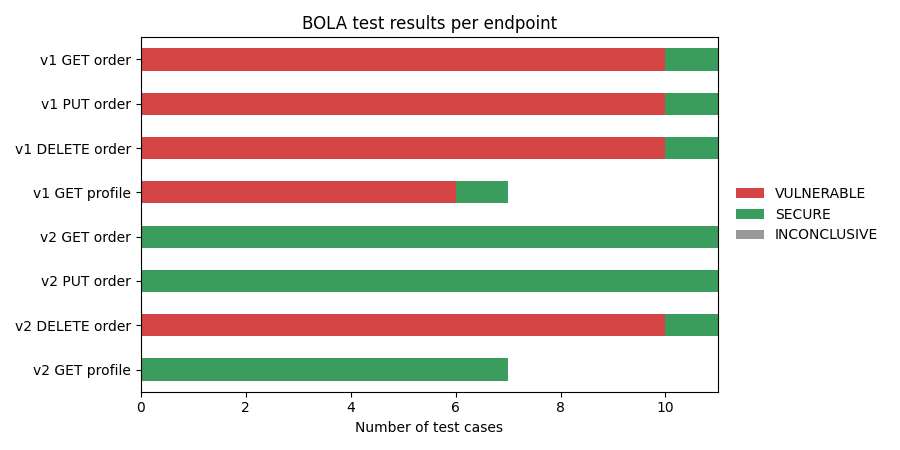

In [5]:
fig, ax = plt.subplots(figsize=(9, 4.5))
summary[["VULNERABLE", "SECURE", "INCONCLUSIVE"]].plot(
    kind="barh", stacked=True, ax=ax, color=["#d64545", "#3a9d5d", "#999999"])
ax.set_xlabel("Number of test cases")
ax.set_ylabel("")
ax.set_title("BOLA test results per endpoint")
ax.invert_yaxis()
ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), frameon=False)
plt.tight_layout()
plt.show()

In [6]:
findings = (results[results["verdict"] == "VULNERABLE"]
            .groupby(["endpoint", "severity"]).size().reset_index(name="vulnerable_cases")
            .sort_values("severity", key=lambda s: s.map({"Critical": 0, "High": 1, "Medium": 2})))
print("Findings by severity:")
print(findings.to_string(index=False))

Findings by severity:
       endpoint severity  vulnerable_cases
v1 DELETE order Critical                10
v2 DELETE order Critical                10
   v1 PUT order     High                10
 v1 GET profile     High                 6
   v1 GET order   Medium                10

**Reading the results**

* **v1** endpoints fail every cross-user test: only authentication exists, there is no ownership check.
* **v2** GET/PUT/profile pass, but **`v2 DELETE order`** is still vulnerable: the fix was applied to some handlers and not others.
  This is exactly the type of regression automated, matrix-style testing is designed to catch.

## 5. Postman collection and Newman

The same test matrix is exported as a Postman collection (v2.1). Each request logs in as the attacker, targets the victim's object and asserts
the response is `401/403/404`. The collection can be imported into Postman or run headless with **Newman** in CI.

In [7]:
def build_postman_collection():
    items = []
    # login requests store one token per user in collection variables
    login_folder = {"name": "00 - Authentication", "item": []}
    for user, creds in USERS.items():
        login_folder["item"].append({
            "name": f"Login ({user})",
            "event": [{"listen": "test", "script": {"type": "text/javascript", "exec": [
                "pm.test('login ok', function () { pm.response.to.have.status(200); });",
                f"pm.collectionVariables.set('token_{user}', pm.response.json().token);",
            ]}}],
            "request": {"method": "POST", "header": [{"key": "Content-Type", "value": "application/json"}],
                        "url": "{{baseUrl}}/login",
                        "body": {"mode": "raw", "raw": json.dumps(creds)}},
        })
    items.append(login_folder)

    for endpoint in ENDPOINTS:
        if endpoint["method"] in ("PUT", "PATCH", "DELETE", "POST") and not ALLOW_DESTRUCTIVE:
            continue
        folder = {"name": endpoint["name"], "item": []}
        for victim, object_ids in RESOURCES[endpoint["resource"]].items():
            for object_id in object_ids:
                for attacker in USERS:
                    if attacker == victim:
                        continue
                    request_def = {
                        "method": endpoint["method"],
                        "header": [{"key": "Authorization", "value": "Bearer {{token_%s}}" % attacker},
                                   {"key": "Content-Type", "value": "application/json"}],
                        "url": "{{baseUrl}}" + endpoint["path"].format(id=object_id),
                    }
                    if endpoint.get("body"):
                        request_def["body"] = {"mode": "raw", "raw": json.dumps(endpoint["body"])}
                    folder["item"].append({
                        "name": f"{attacker} -> {victim}'s object {object_id}",
                        "event": [{"listen": "test", "script": {"type": "text/javascript", "exec": [
                            f"pm.test('BOLA: {attacker} must not {endpoint['method']} {victim} object {object_id}', function () {{",
                            "    pm.expect(pm.response.code).to.be.oneOf([401, 403, 404]);",
                            "});",
                        ]}}],
                        "request": request_def,
                    })
        items.append(folder)

    collection = {
        "info": {"name": "API Security Framework - BOLA checks",
                 "schema": "https://schema.getpostman.com/json/collection/v2.1.0/collection.json"},
        "item": items,
        "variable": [{"key": "baseUrl", "value": BASE_URL}] + [{"key": f"token_{u}", "value": ""} for u in USERS],
    }
    if RESET_URL:  # restore seed data before every request so destructive tests stay independent
        collection["event"] = [{"listen": "prerequest", "script": {"type": "text/javascript", "exec": [
            "if (pm.info.requestName.indexOf('Login') === -1) {",
            f"    pm.sendRequest({{url: '{RESET_URL}', method: 'POST'}}, function () {{}});",
            "}",
        ]}}]
    return collection


collection = build_postman_collection()
collection_path = os.path.join(OUTPUT_DIR, "bola_collection.postman.json")
environment_path = os.path.join(OUTPUT_DIR, "local.postman_environment.json")
with open(collection_path, "w") as f:
    json.dump(collection, f, indent=2)
with open(environment_path, "w") as f:
    json.dump({"name": "local", "values": [{"key": "baseUrl", "value": BASE_URL, "enabled": True}]}, f, indent=2)
request_count = sum(len(folder["item"]) for folder in collection["item"])
print(f"Wrote {collection_path} with {request_count} requests.")

Wrote output/bola_collection.postman.json with 75 requests.

In [8]:
newman = shutil.which("newman")
if newman:
    report_path = os.path.join(OUTPUT_DIR, "newman_report.json")
    completed = subprocess.run(
        [newman, "run", collection_path, "-e", environment_path, "--reporters", "cli,json",
         "--reporter-json-export", report_path],
        capture_output=True, text=True)
    print(completed.stdout[-2500:])
else:
    print("Newman is not installed. To run the collection headless:\n"
          "  npm install -g newman\n"
          f"  newman run {collection_path} -e {environment_path}")

Newman is not installed. To run the collection headless:
  npm install -g newman
  newman run output/bola_collection.postman.json -e output/local.postman_environment.json

## 6. OWASP ZAP automation

ZAP is run as a daemon and driven through its API. **Note:** ZAP's active scanner is excellent for injection, misconfiguration and auth issues,
but it cannot know *who owns which object*, so BOLA detection comes from the two-user engine above. ZAP complements it by crawling the API
and surfacing everything else. Start ZAP first, for example:

```bash
zap.sh -daemon -port 8080 -config api.key=changeme
```

In [9]:
ZAP_PROXY = "http://127.0.0.1:8080"
ZAP_API_KEY = os.environ.get("ZAP_API_KEY", "changeme")
RUN_ZAP = True


def run_zap_scan(target, token):
    from zapv2 import ZAPv2  # python-owasp-zap-v2.4
    zap = ZAPv2(apikey=ZAP_API_KEY, proxies={"http": ZAP_PROXY, "https": ZAP_PROXY})
    zap.core.version  # raises if the daemon is not reachable
    # send the attacker's token with every request ZAP makes
    zap.replacer.add_rule(description="auth", enabled=True, matchtype="REQ_HEADER", matchregex=False,
                          matchstring="Authorization", replacement=f"Bearer {token}")
    zap.urlopen(target)
    spider_id = zap.spider.scan(target)
    while int(zap.spider.status(spider_id)) < 100:
        time.sleep(2)
    scan_id = zap.ascan.scan(target)
    while int(zap.ascan.status(scan_id)) < 100:
        time.sleep(5)
    return zap.core.alerts(baseurl=target)


zap_alerts = []
if RUN_ZAP:
    try:
        zap_alerts = run_zap_scan(BASE_URL, login("alice"))
        zap_df = pd.DataFrame(zap_alerts)[["risk", "alert", "url"]]
        print(zap_df.groupby(["risk", "alert"]).size())
        zap_df.to_csv(os.path.join(OUTPUT_DIR, "zap_alerts.csv"), index=False)
    except ImportError:
        print("ZAP client missing: pip install python-owasp-zap-v2.4")
    except Exception as error:  # daemon not running, wrong API key, etc.
        print(f"ZAP scan skipped ({type(error).__name__}): start the ZAP daemon and re-run this cell.")

ZAP client missing: pip install python-owasp-zap-v2.4

## 7. Reports and CI gate

In [10]:
results.to_csv(os.path.join(OUTPUT_DIR, "bola_results.csv"), index=False)
results.to_json(os.path.join(OUTPUT_DIR, "bola_results.json"), orient="records", indent=2)

lines = ["# BOLA Test Report", "", f"Total test cases: {len(results)}",
         f"Vulnerable: {total_vulnerable}", "", "| Endpoint | Vulnerable | Secure | Exposure % |", "|---|---|---|---|"]
for name, row in summary.iterrows():
    lines.append(f"| {name} | {int(row['VULNERABLE'])} | {int(row['SECURE'])} | {row['exposure_%']} |")
with open(os.path.join(OUTPUT_DIR, "bola_report.md"), "w") as f:
    f.write("\n".join(lines))

critical_or_high = int(results["severity"].isin(["Critical", "High"]).sum())
exit_code = 1 if critical_or_high else 0
print(f"Critical/High findings: {critical_or_high}  ->  CI gate {'FAILED' if exit_code else 'PASSED'} (exit code {exit_code})")
print("Files written to ./output:", sorted(os.listdir(OUTPUT_DIR)))

Critical/High findings: 36  ->  CI gate FAILED (exit code 1)
Files written to ./output: ['bola_collection.postman.json', 'bola_report.md', 'bola_results.csv', 'bola_results.json', 'local.postman_environment.json']

## 8. Remediation guidance

Fix object-level authorization **server-side, on every handler**:

```python
order = Order.query.get_or_404(order_id)
if order.owner_id != current_user.id:      # ownership check on EVERY method
    abort(403)                              # (or 404 to avoid confirming the object exists)
```

* Centralise the check (decorator, middleware or query scoping such as `Order.query.filter_by(owner_id=current_user.id)`) so new endpoints cannot forget it.
* Prefer unpredictable identifiers (UUIDs), but never rely on them as the only control.
* Re-run this notebook / the Newman collection in CI on every release to catch regressions like the missed `v2 DELETE`.

In [11]:
if demo_server:
    demo_server.stop()
    print("Demo API stopped.")

Demo API stopped.